# 12 - GAEZ v5 Suitability at 1 km (30 arc-seconds)

Until now the warehouse carried the GAEZ v5 suitability index and class at **5 arc-minutes (~9 km)**: the files under
`MAPSET/RES05-SXX` and `MAPSET/RES05-SIX`. Only 164 GAEZ pixels cover Banten, so every 1 km cell inside one of them
shares the same ten values and the crop map comes out in ~9 km blocks.

GAEZ v5 also publishes the same variables at **30 arc-seconds (~1 km)**, in the sibling folders `RES05-SXX30AS`
(index, 0-10,000) and `RES05-SIX30AS` (class), with exactly the scenario used here: historical climate 2001-2020
(`HP0120`, AgERA5), irrigated high-input management (`HILM`). This notebook adds them for all ten crops.

* The global files are Cloud-Optimized GeoTIFFs (tiled, with overviews), so only the Banten window is read over HTTP
  (GDAL `/vsicurl/`): a few hundred kB per crop instead of 50-230 MB per global file. The clips land in the lake
  (`datasets/raw/gaez_v5_30as/`).
* Zonal statistics onto the 1 km grid (mean for the index, majority for the class, `all_touched=True`, the same
  convention as notebook 04) become new columns `gaez1k_index_<crop>` / `gaez1k_class_<crop>` in
  `tabular_features.csv`. The ~9 km columns stay untouched, so everything built on them remains reproducible.
* The rain-fed scenario (`HRLM`) of the first four crops is read as well and stored as audit columns
  `gaez1k_index_<crop>_rainfed` / `gaez1k_class_<crop>_rainfed`, mirroring the ~9 km audit columns of notebook 07.

In [1]:
import os
import time
from pathlib import Path

import geopandas as gpd
import numpy as np
import pandas as pd
import rasterio
from rasterio.windows import from_bounds
from rasterstats import zonal_stats

NOTEBOOK_DIR = Path(os.path.abspath("."))
if NOTEBOOK_DIR.name != "preprocessing":
    NOTEBOOK_DIR = NOTEBOOK_DIR / "scripts" / "preprocessing"
os.chdir(NOTEBOOK_DIR)

PROJECT_ROOT = NOTEBOOK_DIR.parents[1]
RAW_DIR = PROJECT_ROOT / "datasets" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "datasets" / "processed"
GAEZ1K_DIR = RAW_DIR / "gaez_v5_30as"
GAEZ1K_DIR.mkdir(parents=True, exist_ok=True)
FEATURES_CSV = PROCESSED_DIR / "features" / "tabular_features.csv"

URL = ("/vsicurl/https://storage.googleapis.com/fao-gismgr-gaez-v5-data/DATA/GAEZ-V5/MAPSET/{variable}/"
       "GAEZ-V5.{variable}.HP0120.AGERA5.HIST.{code}.{water}.tif")
CROP_CODES = {"rice": "RCW", "maize": "MZE", "cassava": "CSV", "soybean": "SOY", "oilpalm": "OLP",
              "rubber": "RUB", "sugarcane": "SUC", "coffee": "COF", "cacao": "COC", "coconut": "CON"}
VARIABLES = {"RES05-SXX30AS": "suitability_index", "RES05-SIX30AS": "suitability_class"}
# (water / input level, file tag, column suffix, crops): irrigated high input for all ten crops (the scenario every
# analysis uses), plus the rain-fed scenario of the first four crops as audit columns, as at ~9 km (notebook 07)
SCENARIOS = [("HILM", "irrigated", "", list(CROP_CODES)),
             ("HRLM", "rainfed", "_rainfed", ["rice", "maize", "cassava", "soybean"])]
BBOX = (104.95, -7.20, 106.95, -5.60)   # Banten grid extent in WGS84 plus a margin
NODATA = -9
print("lake folder:", GAEZ1K_DIR)

lake folder: D:\Softwares\AnacondaProjects\GeoSuitability_AI_Analytics\datasets\raw\gaez_v5_30as


## 1. Read the Banten window of every global 1 km raster (remote, windowed)

In [2]:
GDAL_HTTP = dict(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", CPL_VSIL_CURL_ALLOWED_EXTENSIONS=".tif",
                 GDAL_HTTP_MAX_RETRY="4", GDAL_HTTP_RETRY_DELAY="2")
paths = {}
for water, tag, suffix, crops in SCENARIOS:
    for crop in crops:
        code = CROP_CODES[crop]
        for variable, label in VARIABLES.items():
            dest = GAEZ1K_DIR / f"{label}_{crop}_{code}_{tag}_30as.tif"
            paths[(crop + suffix, label)] = dest
            if dest.exists():
                continue
            t0 = time.time()
            with rasterio.Env(**GDAL_HTTP), rasterio.open(URL.format(variable=variable, code=code, water=water)) as src:
                window = from_bounds(*BBOX, src.transform).round_offsets().round_lengths()
                data = src.read(1, window=window)
                profile = {"driver": "GTiff", "dtype": data.dtype, "count": 1, "crs": src.crs, "nodata": src.nodata,
                           "height": data.shape[0], "width": data.shape[1], "transform": src.window_transform(window),
                           "compress": "deflate"}
            with rasterio.open(dest, "w", **profile) as dst:
                dst.write(data, 1)
            print(f"{dest.name}: {data.shape}, values {data[data != NODATA].min()}..{data.max()}, {time.time() - t0:.0f}s", flush=True)
print(len(paths), "clipped rasters in", GAEZ1K_DIR)

suitability_index_rice_RCW_rainfed_30as.tif: (192, 240), values 0..9823, 8s


suitability_class_rice_RCW_rainfed_30as.tif: (192, 240), values 1..10, 7s


suitability_index_maize_MZE_rainfed_30as.tif: (192, 240), values 0..5556, 9s


suitability_class_maize_MZE_rainfed_30as.tif: (192, 240), values 3..10, 7s


suitability_index_cassava_CSV_rainfed_30as.tif: (192, 240), values 0..9753, 9s


suitability_class_cassava_CSV_rainfed_30as.tif: (192, 240), values 1..10, 7s


suitability_index_soybean_SOY_rainfed_30as.tif: (192, 240), values 0..7249, 9s


suitability_class_soybean_SOY_rainfed_30as.tif: (192, 240), values 2..10, 7s


28 clipped rasters in D:\Softwares\AnacondaProjects\GeoSuitability_AI_Analytics\datasets\raw\gaez_v5_30as


In [3]:
# Class codes in the 1 km raster (FAO legend: 1-8 suitability classes, 9 = no cropland, 10 = water incl. sea)
with rasterio.open(paths[("rice", "suitability_class")]) as s:
    vals, counts = np.unique(s.read(1), return_counts=True)
print(dict(zip(vals.tolist(), counts.tolist())))

{1: 27, 2: 2043, 3: 1262, 4: 1362, 5: 2452, 6: 3779, 7: 5436, 8: 1848, 9: 1388, 10: 26483}


## 2. Zonal statistics onto the 1 km grid and merge into the warehouse table

Class codes of the 1 km product (FAO's legend for these rasters, checked against the index values): 1-7 very high to
very marginal, 8 not suitable, 9 no cropland (land GAEZ leaves out for that crop and scenario; the index is -1
there) and 10 water, here mostly sea (the index carries -9, -1 or 0 on those pixels). Averaging the special codes in
would drag coastal cells down, so only pixels with a real suitability class (1-8) enter the index mean, and class 10
is ignored for the class majority. A cell without such a pixel stays empty: open water, or land GAEZ marks as no
cropland for that crop.

In [4]:
grid = gpd.read_file(PROCESSED_DIR / "grid" / "grid_1km.gpkg").to_crs("EPSG:4326")
stats = grid[["grid_id"]].copy()
t0 = time.time()
for key in [crop + suffix for _, _, suffix, crops in SCENARIOS for crop in crops]:   # e.g. rice, ..., rice_rainfed
    with rasterio.open(paths[(key, "suitability_index")]) as s_idx, rasterio.open(paths[(key, "suitability_class")]) as s_cls:
        index, klass, affine = s_idx.read(1).astype("int16"), s_cls.read(1).astype("int16"), s_idx.transform
    land = (klass >= 1) & (klass <= 8) & (index >= 0)
    idx = zonal_stats(grid.geometry, np.where(land, index, NODATA), affine=affine, stats=["mean"], nodata=NODATA, all_touched=True)
    stats[f"gaez1k_index_{key}"] = [s["mean"] for s in idx]
    cls = zonal_stats(grid.geometry, np.where(klass == 10, NODATA, klass), affine=affine, stats=["majority"], nodata=NODATA,
                      all_touched=True)
    stats[f"gaez1k_class_{key}"] = [s["majority"] for s in cls]
    print(f"{key}: {stats[f'gaez1k_index_{key}'].notna().sum()}/{len(stats)} cells got a value", flush=True)
print(f"zonal statistics done in {time.time() - t0:.0f}s")
stats.to_csv(PROCESSED_DIR / "features" / "gaez1k_zonal_stats.csv", index=False)

rice: 9129/9333 cells got a value


maize: 9129/9333 cells got a value


cassava: 9129/9333 cells got a value


soybean: 9129/9333 cells got a value


oilpalm: 9129/9333 cells got a value


rubber: 9129/9333 cells got a value


... (5 outputs left out)

maize_rainfed: 9310/9333 cells got a value


cassava_rainfed: 9310/9333 cells got a value


soybean_rainfed: 9310/9333 cells got a value


zonal statistics done in 171s


In [5]:
features = pd.read_csv(FEATURES_CSV)
features = features.drop(columns=[c for c in features.columns if c.startswith("gaez1k_")])   # idempotent re-run
features = features.merge(stats, on="grid_id", how="left")
features.to_csv(FEATURES_CSV, index=False)
print(features.shape, "->", FEATURES_CSV)

(9333, 91) -> D:\Softwares\AnacondaProjects\GeoSuitability_AI_Analytics\datasets\processed\features\tabular_features.csv


## 3. What the 1 km version adds

In [6]:
rows = []
pix = (np.floor((90 - features["lat"]) * 12) * 100000 + np.floor((features["lon"] + 180) * 12))
for crop in CROP_CODES:
    a, b = features[f"gaez_index_{crop}"], features[f"gaez1k_index_{crop}"]
    ok = b.notna()
    within = (b[ok] - b[ok].groupby(pix[ok]).transform("mean")).var() / b[ok].var()
    rows.append({"crop": crop, "cells with a 1 km value": int(ok.sum()), "distinct values ~9 km": a.nunique(),
                 "distinct values 1 km": b.nunique(), "Spearman ~9 km vs 1 km": a[ok].rank().corr(b[ok].rank()),
                 "variance inside ~9 km pixels (1 km)": within, "suitable cells ~9 km": int((a >= 5000).sum()),
                 "suitable cells 1 km": int((b >= 5000).sum())})
summary = pd.DataFrame(rows).set_index("crop")
summary.round(3)

,cells with a 1 km value,distinct values ~9 km,distinct values 1 km,Spearman ~9 km vs 1 km,variance inside ~9 km pixels (1 km),suitable cells ~9 km,suitable cells 1 km
crop,,,,,,,
rice,9129,525,7647,0.888,0.181,2001,2181
maize,9129,507,6384,0.887,0.200,0,8
cassava,9129,525,7903,0.882,0.222,3154,3060
soybean,9129,519,6926,0.867,0.234,87,256
oilpalm,9129,522,7866,0.875,0.248,3957,3938
rubber,9129,502,6076,0.817,0.317,0,0
sugarcane,9129,509,7310,0.894,0.203,669,1186
coffee,9310,518,7934,0.884,0.205,2660,3110
cacao,9310,518,7749,0.858,0.252,1297,2508


In [7]:
missing = features[[f"gaez1k_index_{c}" for c in CROP_CODES]].isna().all(axis=1)
lc = {10: "Tree cover", 30: "Grassland", 40: "Cropland", 50: "Built-up", 60: "Bare", 80: "Water", 90: "Wetland", 95: "Mangroves"}
print(f"{int(missing.sum())} cells have no 1 km GAEZ value for any crop (open water); their majority land cover:")
print(features.loc[missing, "landcover_majority"].map(lc).value_counts().to_string())

23 cells have no 1 km GAEZ value for any crop (open water); their majority land cover:
landcover_majority
Water    23


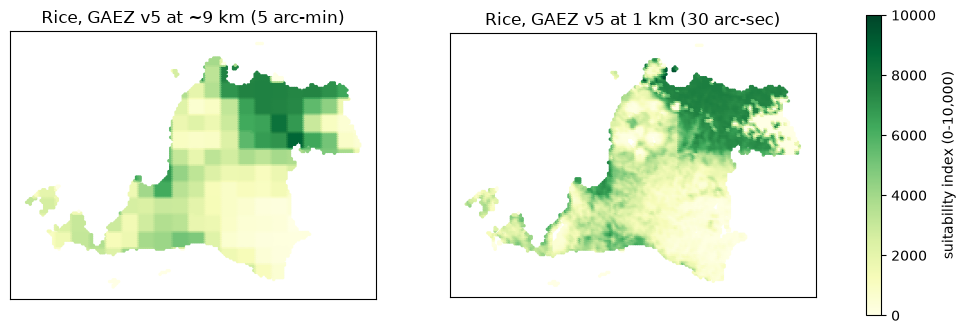

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, (col, title) in zip(axes, [("gaez_index_rice", "Rice, GAEZ v5 at ~9 km (5 arc-min)"),
                                   ("gaez1k_index_rice", "Rice, GAEZ v5 at 1 km (30 arc-sec)")]):
    sc = ax.scatter(features["lon"], features["lat"], c=features[col], s=2.2, cmap="YlGn", vmin=0, vmax=10000)
    ax.set(title=title, aspect="equal"); ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(sc, ax=axes, shrink=0.75, label="suitability index (0-10,000)")
fig.savefig(NOTEBOOK_DIR / "gaez_9km_vs_1km_rice.png", dpi=130, bbox_inches="tight")
plt.show()

## Done

`tabular_features.csv` now carries both resolutions: `gaez_index_*` / `gaez_class_*` (~9 km, as before) and
`gaez1k_index_*` / `gaez1k_class_*` (1 km), each with rain-fed audit columns for the first four crops (`*_rainfed`).
The dashboard uses the 1 km version by default and can switch back to ~9 km for comparison. The modeling notebooks
m01-m12 learn the 1 km target; m13 compares it with the ~9 km one.